# Ghost Pharmacies

When Bay Area pharmacies closed, did people in cheaper homes lose their nearest pharmacy more often?

This one notebook goes from the raw files in `data/` to every number, chart and map we report.
**Rule:** before submitting, do *Runtime → Restart and run all* (or `Kernel → Restart & Run All`) and make sure it finishes without errors.

Build steps follow the Team Master Guide. Write your name next to the step you own.

## Step 0. Setup
Runs in both Google Colab and a local Jupyter. Edit only the paths in this cell.

In [1]:
import os, sys, random
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "folium"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    # Shared Drive folder that holds the raw files and receives outputs. Change if yours differs.
    PROJECT_DIR = Path("/content/drive/MyDrive/ghost-pharmacies")
else:
    # Local: the repository root (this notebook lives in notebooks/).
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = PROJECT_DIR / "data"        # raw files, never edited
OUT_DIR = PROJECT_DIR / "outputs"      # everything the notebook creates
FIG_DIR = OUT_DIR / "figures"
MAP_DIR = OUT_DIR / "maps"
for d in (OUT_DIR, FIG_DIR, MAP_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Raw file names. Rename here if the event files are named differently.
PLACES_CSV = DATA_DIR / "google_maps.csv"
ZILLOW_CSVS = [DATA_DIR / n for n in ["zillow_part1.csv", "zillow_part2.csv", "zillow_part3.csv"]]   # full Zillow file, in parts: read all and concatenate
CENSUS_CSV = DATA_DIR / "census_tracts.csv"   # optional

# One seed, used everywhere (train/test split, sampling, models).
SEED = 42
random.seed(SEED)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import folium

np.random.seed(SEED)
pd.set_option("display.max_columns", 50)

print("Colab" if IN_COLAB else "Local", "| project dir:", PROJECT_DIR)
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| sklearn", sklearn.__version__, "| folium", folium.__version__)

Local | project dir: /Users/brianlee/ghost-pharmacies
python 3.14.5 | pandas 3.1.1 | numpy 2.4.6 | sklearn 1.9.1 | folium 0.20.0


### Check the raw files
Confirms each file is in place and has the columns the guide relies on. Reads only the header row, so it is fast even on the 500 MB file.

In [2]:
ZILLOW_COLS = ["zpid", "latitude", "longitude", "county", "bedrooms", "homeStatus", "price",
               "rentZestimate", "getting_around_scores"]
EXPECTED = {
    PLACES_CSV: ["place_id", "name", "category", "lat", "lon", "permanently_closed", "top_reviews"],
    **{p: ZILLOW_COLS for p in ZILLOW_CSVS},
}

for path, cols in EXPECTED.items():
    if not path.exists():
        print(f"MISSING  {path.name}: put it in {DATA_DIR}")
        continue
    header = pd.read_csv(path, nrows=0).columns
    missing = [c for c in cols if c not in header]
    size_mb = path.stat().st_size / 1e6
    status = "OK      " if not missing else "CHECK   "
    print(f"{status} {path.name} ({size_mb:,.0f} MB, {len(header)} columns)"
          + (f" missing: {missing}" if missing else ""))

print("Census (optional):", "found" if CENSUS_CSV.exists() else "not added")

OK       google_maps.csv (506 MB, 41 columns)
OK       zillow_part1.csv (1,495 MB, 140 columns)
OK       zillow_part2.csv (3,934 MB, 140 columns)
OK       zillow_part3.csv (2,006 MB, 140 columns)
Census (optional): not added


## Step 1. Build the pharmacy table
Owner: ___  
Load Places with `usecols`, keep `category == 'Pharmacy'` (expect about 1,694), add the `chain` column, print closures per chain and compare with the guide.

In [3]:
cols = ['place_id', 'name', 'category', 'lat', 'lon', 'permanently_closed', 'top_reviews'] # get needed columns
p = pd.read_csv(PLACES_CSV, usecols=cols, low_memory=False)
print(len(p))

pharmacies = p[p.category == 'Pharmacy'].copy()
print(len(pharmacies), pharmacies.permanently_closed.sum()) #num pharmacies and num closed

# chains table
CHAINS = [
    ('Walgreens', ['walgreens']),
    ('CVS', ['cvs', 'target']),
    ('Rite Aid', ['rite aid']),
    ('Lucky', ['lucky', 'save mart']),
    ('Safeway', ['safeway']),
    ('Costco', ['costco']),
    ('Walmart', ['walmart']),
    ('Kaiser', ['kaiser']),
    ('Rayleys', ['raley', 'nob hill']), ]

# if chain keywords appear in name, identify as a chain
def chain_of(name):
    n = str(name).lower()
    for chain, keys in CHAINS:
        if any(k in n for k in keys):
            return chain
    return 'Independent'
pharmacies['chain'] = pharmacies['name'].apply(chain_of)
pharmacies.drop(columns='top_reviews').head(10)

147429
1692 524


,place_id,name,category,lat,lon,permanently_closed,chain
44,ChIJJ7Ibd1t8j4ARZ2FG0Xw7Y_s,Walgreens Pharmacy,Pharmacy,37.700780,-122.484303,False,Walgreens
128,ChIJMfTsjB9nhYAR6n_6ZjC7bYQ,Diablo Professional Pharmacy,Pharmacy,37.984643,-122.036154,True,Independent
337,ChIJq6o2ZguQhYAREvFyBFAIWt4,Pharmaca Integrative Pharmacy,Pharmacy,37.904155,-122.542290,True,Independent
509,ChIJeWbogxgyjoART71-F7zRwY0,Safeway Pharmacy,Pharmacy,37.267140,-121.833175,False,Safeway
571,ChIJDzdZCOZvhYARO8EgyzmimLQ,Rite Aid Pharmacy,Pharmacy,38.054624,-122.155252,True,Rite Aid
691,ChIJy-NyFsWPj4ARGN85LlnT8VQ,Medical Arts Pharmacy,Pharmacy,37.714412,-122.142271,False,Independent
858,ChIJk_jA5oUgjoAR8jz3mH9C540,Walgreens Pharmacy,Pharmacy,37.129916,-121.638607,False,Walgreens
861,ChIJC5cXpzeQj4ARZCRQ_sy53tA,Walgreens Pharmacy,Pharmacy,37.685806,-122.138247,False,Walgreens
971,ChIJs2suXUCij4ARIAN1d1HeY5o,Rph,Pharmacy,37.500029,-122.241142,False,Independent
1061,ChIJDe8uw6Z-hYARGsgDDkGZbP0,CVS Pharmacy,Pharmacy,37.881282,-122.269022,False,CVS


## Step 2. Decide which closures are real
Owner: ___  
Distance from each closed pharmacy to the nearest open one (BallTree, haversine). Real closure = not Rite Aid or Lucky and no open pharmacy within 50 m (expect about 358). Save `outputs/pharmacies_clean.csv`.

In [4]:
def distance(lat1, lon1, lat2, lon2): #haversine formula -> distance in meters between two lat/lon points on earth
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2]) # convert to radians
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2 #distance between two points on sphere
    return 2 * 6371000 * np.arcsin(np.sqrt(a)) # turn a into meters

pharmacies = pharmacies.dropna(subset=['lat', 'lon']).copy() #pharmacies with no coordinates
open_pharm = pharmacies[pharmacies.permanently_closed == False] #tables of pharmacies still open

def nearest_open(row):
    return distance(row.lat, row.lon, open_pharm.lat.values, open_pharm.lon.values).min()

closed = pharmacies.permanently_closed == True 
pharmacies.loc[closed, 'm_to_open'] = pharmacies[closed].apply(nearest_open, axis=1) # for closed pharmacies store meters to the nearest open pharmacy

pharmacies['chain_shutdown'] = pharmacies.chain.isin(['Rite Aid', 'Lucky']) #flag rite aid and lucky as chain shutdown
pharmacies['real_closure'] = closed & ~pharmacies.chain_shutdown & (pharmacies.m_to_open > 50) # real closure -> closed, not a chain shutdown, no open pharmacy within 50m

print(closed.sum(), pharmacies.real_closure.sum())
pharmacies.to_csv(OUT_DIR / 'pharmacies_clean.csv', index=False)
    

524 358


## Step 3. Hand-check
Owner: ___  
30 real closures + 10 open pharmacies sampled with `SEED`, checked on Google Maps. Load the results table here and report the error rate.

In [5]:
sample = pd.concat([
    pharmacies[pharmacies.real_closure].sample(30, random_state=SEED),
    pharmacies[pharmacies.permanently_closed == False].sample(10, random_state=SEED),
]) #random sample
sample[['name', 'chain', 'lat', 'lon', 'real_closure']].to_csv(OUT_DIR / 'handcheck.csv', index=False) 
# handchecked_done is in outputs

In [6]:
# scoring cell

done = pd.read_csv(OUT_DIR / 'handcheck_done.csv')
wrong = (done['correct'].str.lower() == 'no').sum() 
print(f"{wrong} wrong out of {len(done)} = {wrong / len(done):.0%} error rate")

2 wrong out of 40 = 5% error rate


## Step 4. Build the rent level
Owner: ___  
Load Zillow (use `chunksize` if needed), drop missing coordinates, compute rent and relative rent by bedrooms, keep \$500 to \$20,000 and 0 to 5 bedrooms, split into thirds within county.

In [7]:
# 4.1: processing the 3 zillow files into 1 table
pieces = []
for i in range(len(ZILLOW_CSVS)):
    reader = pd.read_csv(ZILLOW_CSVS[i], usecols=ZILLOW_COLS, chunksize=50000)
    for chunk in reader:
        chunk["row_source"] = i + 1 # tagging each row for easy reference to its file origin
        pieces.append(chunk)
mergedTable = pd.concat(pieces, ignore_index=True)

In [8]:
# confirmation of 4.1 implementation
display(mergedTable.head(10))
print(len(mergedTable))
print(mergedTable.dtypes)
print(mergedTable["zpid"].duplicated().sum())
print(mergedTable["row_source"].value_counts())

,zpid,homeStatus,bedrooms,price,longitude,latitude,rentZestimate,county,getting_around_scores,row_source
0,2073071533,FOR_RENT,2.0,5094,-122.263677,37.510161,NaN,San Mateo County,"{""bike_score"":""66/100 | Bikeable"",""transit_sco...",1
1,2077933815,FOR_RENT,3.0,5614,-122.025500,37.376560,NaN,Santa Clara County,"{""bike_score"":""84/100 | Very Bikeable"",""transi...",1
2,19253238,RECENTLY_SOLD,4.0,1850000,-122.532330,37.922455,NaN,Marin County,"{""bike_score"":""43/100 | Somewhat Bikeable"",""tr...",1
3,326139325,RECENTLY_SOLD,1.0,749000,-122.456100,37.764890,5221.0,San Francisco County,"{""bike_score"":""67/100 | Bikeable"",""transit_sco...",1
4,2089306902,FOR_RENT,3.0,5819,-121.932376,37.347085,NaN,Santa Clara County,"{""bike_score"":""79/100 | Very Bikeable"",""transi...",1
5,2067771850,FOR_RENT,0.0,2095,-122.415020,37.788602,NaN,San Francisco County,"{""bike_score"":""70/100 | Very Bikeable"",""transi...",1
6,19278440,RECENTLY_SOLD,3.0,679000,-122.570625,38.117126,3929.0,Marin County,"{""bike_score"":""29/100 | Somewhat Bikeable"",""tr...",1
7,299071045,RECENTLY_SOLD,4.0,840000,-122.024370,37.596542,2963.0,Alameda County,"{""bike_score"":""59/100 | Bikeable"",""transit_sco...",1
8,18402887,RECENTLY_SOLD,4.0,1150000,-122.088776,37.949580,5115.0,Contra Costa County,"{""bike_score"":""51/100 | Bikeable"",""transit_sco...",1
9,18384685,RECENTLY_SOLD,4.0,1452000,-122.036670,37.931816,4582.0,Contra Costa County,"{""bike_score"":""86/100 | Very Bikeable"",""transi...",1


148005
zpid                       int64
homeStatus                   str
bedrooms                 float64
price                      int64
longitude                float64
latitude                 float64
rentZestimate            float64
county                       str
getting_around_scores        str
row_source                 int64
dtype: object
0
row_source
2    78424
3    39867
1    29714
Name: count, dtype: int64


In [9]:
# 4.2: visualizing data before changing anything
print(mergedTable["homeStatus"].value_counts())
print(mergedTable["county"].value_counts())
print(mergedTable.isna().mean())
print(mergedTable.groupby("homeStatus")["price"].median())

homeStatus
FOR_RENT         74343
RECENTLY_SOLD    61606
FOR_SALE         12056
Name: count, dtype: int64
county
Santa Clara County      38559
Alameda County          34588
Contra Costa County     19512
San Francisco County    15652
San Mateo County        13702
Sonoma County           10216
Solano County            8442
Marin County             4474
Napa County              2860
Name: count, dtype: int64
zpid                     0.000000
homeStatus               0.000000
bedrooms                 0.015452
price                    0.000000
longitude                0.005371
latitude                 0.005371
rentZestimate            0.513354
county                   0.000000
getting_around_scores    0.000000
row_source               0.000000
dtype: float64
homeStatus
FOR_RENT            3109.0
FOR_SALE          949000.0
RECENTLY_SOLD    1103500.0
Name: price, dtype: float64


In [10]:
# 4.3: Clean data, drop homes w no locations
homes = mergedTable.dropna(subset=["longitude", "latitude"])
print("rows after:", len(homes))


rows after: 147210


In [11]:
# 4.4: compute rent
homes["rent"] = np.where(homes["homeStatus"] == "FOR_RENT", homes["price"], homes["rentZestimate"])
print(homes["rent"].isna().groupby(homes["homeStatus"]).mean())

# 4.5: filter out noise
# keep contains T/F list that lines up with the rows of homes, rows that line up with F are dropped from homes
keep = homes["rent"].between(500, 20000) & homes["bedrooms"].between(0, 5)
homes = homes[keep]
# sanity check
print("rows after 4.5:", len(homes))
homes["homeStatus"].value_counts()


homeStatus
FOR_RENT         0.000000
FOR_SALE         0.302618
RECENTLY_SOLD    0.086632
Name: rent, dtype: float64
rows after 4.5: 134835


homeStatus
FOR_RENT         73519
RECENTLY_SOLD    53588
FOR_SALE          7728
Name: count, dtype: int64

In [12]:
# 4.6: relative rent price so we can more accurately map what is a "cheap home"
# groupby to sort rows into groups by # beds, specified that the rent values are the values in the groups, then got the median
homes["rel_rent"] = homes["rent"] / homes.groupby("bedrooms")["rent"].transform("median")
display(homes.head(10))
# sanity check
print(homes.groupby("bedrooms")["rent"].agg(["count", "median"]))


# 4.7: label each homes rel rent by low, middle, high comparative to county so we can analyze impact of closing pharmas
prcnt_by_row = homes.groupby("county")["rel_rent"].rank(pct=True, method="first") # rank gives percentile of the rel_rent relative to the group
homes["rent_tier"] = pd.cut(prcnt_by_row, bins=[0, 1/3, 2/3, 1], labels=["low", "middle", "high"]) # sorts the prcnts into the labels and makes a new col
display(homes.head(10))
# sanity check
print(len(prcnt_by_row) == len(homes))
print(pd.crosstab(homes["county"], homes["rent_tier"]))
print(homes["rent_tier"].isna().sum())

,zpid,homeStatus,bedrooms,price,longitude,latitude,rentZestimate,county,getting_around_scores,row_source,rent,rel_rent
0,2073071533,FOR_RENT,2.0,5094,-122.263677,37.510161,NaN,San Mateo County,"{""bike_score"":""66/100 | Bikeable"",""transit_sco...",1,5094.0,1.482106
1,2077933815,FOR_RENT,3.0,5614,-122.025500,37.376560,NaN,Santa Clara County,"{""bike_score"":""84/100 | Very Bikeable"",""transi...",1,5614.0,1.337622
3,326139325,RECENTLY_SOLD,1.0,749000,-122.456100,37.764890,5221.0,San Francisco County,"{""bike_score"":""67/100 | Bikeable"",""transit_sco...",1,5221.0,1.802831
4,2089306902,FOR_RENT,3.0,5819,-121.932376,37.347085,NaN,Santa Clara County,"{""bike_score"":""79/100 | Very Bikeable"",""transi...",1,5819.0,1.386467
5,2067771850,FOR_RENT,0.0,2095,-122.415020,37.788602,NaN,San Francisco County,"{""bike_score"":""70/100 | Very Bikeable"",""transi...",1,2095.0,0.859664
6,19278440,RECENTLY_SOLD,3.0,679000,-122.570625,38.117126,3929.0,Marin County,"{""bike_score"":""29/100 | Somewhat Bikeable"",""tr...",1,3929.0,0.936145
7,299071045,RECENTLY_SOLD,4.0,840000,-122.024370,37.596542,2963.0,Alameda County,"{""bike_score"":""59/100 | Bikeable"",""transit_sco...",1,2963.0,0.602358
8,18402887,RECENTLY_SOLD,4.0,1150000,-122.088776,37.949580,5115.0,Contra Costa County,"{""bike_score"":""51/100 | Bikeable"",""transit_sco...",1,5115.0,1.039845
9,18384685,RECENTLY_SOLD,4.0,1452000,-122.036670,37.931816,4582.0,Contra Costa County,"{""bike_score"":""86/100 | Very Bikeable"",""transi...",1,4582.0,0.931490
11,2055832490,FOR_RENT,1.0,2195,-122.098081,37.395047,NaN,Santa Clara County,"{""bike_score"":null,""transit_score"":""45/100 | S...",1,2195.0,0.757942


          count  median
bedrooms               
0.0        7876  2437.0
1.0       34744  2896.0
2.0       42133  3437.0
3.0       28442  4197.0
4.0       17027  4919.0
5.0        4613  5747.0


,zpid,homeStatus,bedrooms,price,longitude,latitude,rentZestimate,county,getting_around_scores,row_source,rent,rel_rent,rent_tier
0,2073071533,FOR_RENT,2.0,5094,-122.263677,37.510161,NaN,San Mateo County,"{""bike_score"":""66/100 | Bikeable"",""transit_sco...",1,5094.0,1.482106,high
1,2077933815,FOR_RENT,3.0,5614,-122.025500,37.376560,NaN,Santa Clara County,"{""bike_score"":""84/100 | Very Bikeable"",""transi...",1,5614.0,1.337622,high
3,326139325,RECENTLY_SOLD,1.0,749000,-122.456100,37.764890,5221.0,San Francisco County,"{""bike_score"":""67/100 | Bikeable"",""transit_sco...",1,5221.0,1.802831,high
4,2089306902,FOR_RENT,3.0,5819,-121.932376,37.347085,NaN,Santa Clara County,"{""bike_score"":""79/100 | Very Bikeable"",""transi...",1,5819.0,1.386467,high
5,2067771850,FOR_RENT,0.0,2095,-122.415020,37.788602,NaN,San Francisco County,"{""bike_score"":""70/100 | Very Bikeable"",""transi...",1,2095.0,0.859664,low
6,19278440,RECENTLY_SOLD,3.0,679000,-122.570625,38.117126,3929.0,Marin County,"{""bike_score"":""29/100 | Somewhat Bikeable"",""tr...",1,3929.0,0.936145,low
7,299071045,RECENTLY_SOLD,4.0,840000,-122.024370,37.596542,2963.0,Alameda County,"{""bike_score"":""59/100 | Bikeable"",""transit_sco...",1,2963.0,0.602358,low
8,18402887,RECENTLY_SOLD,4.0,1150000,-122.088776,37.949580,5115.0,Contra Costa County,"{""bike_score"":""51/100 | Bikeable"",""transit_sco...",1,5115.0,1.039845,high
9,18384685,RECENTLY_SOLD,4.0,1452000,-122.036670,37.931816,4582.0,Contra Costa County,"{""bike_score"":""86/100 | Very Bikeable"",""transi...",1,4582.0,0.931490,high
11,2055832490,FOR_RENT,1.0,2195,-122.098081,37.395047,NaN,Santa Clara County,"{""bike_score"":null,""transit_score"":""45/100 | S...",1,2195.0,0.757942,low


True
rent_tier               low  middle   high
county                                    
Alameda County        10869   10870  10870
Contra Costa County    6079    6079   6080
Marin County           1255    1255   1256
Napa County             788     788    788
San Francisco County   4541    4542   4542
San Mateo County       3928    3928   3928
Santa Clara County    11866   11867  11867
Solano County          2629    2629   2630
Sonoma County          2987    2987   2987
0


In [13]:
# 4.8: create col for numeric walk score values, if none put NaN
pattern = r'"walk_score":"(\d+)/100'
homes["walk_score"] = homes["getting_around_scores"].str.extract(pattern, expand=False).astype(float) # extractin regex pattern as a collection, turned into floats, and added to new col
display(homes.sample(n=10, random_state=SEED)
)
# sanity check
print(homes["walk_score"].describe(), "\n")
print("percent with walk score:", homes["walk_score"].notna().mean())

,zpid,homeStatus,bedrooms,price,longitude,latitude,rentZestimate,county,getting_around_scores,row_source,rent,rel_rent,rent_tier,walk_score
71847,18304544,RECENTLY_SOLD,3.0,580000,-121.762320,37.955220,2956.0,Contra Costa County,"{""bike_score"":""40/100 | Somewhat Bikeable"",""tr...",2,2956.0,0.704313,low,25.0
128387,19390448,FOR_SALE,3.0,599000,-122.300156,38.312790,3294.0,Napa County,"{""bike_score"":""88/100 | Very Bikeable"",""transi...",3,3294.0,0.784846,low,83.0
134598,2079194705,FOR_RENT,2.0,4097,-121.998373,37.351045,NaN,Santa Clara County,"{""bike_score"":null,""transit_score"":null,""walk_...",3,4097.0,1.192028,middle,NaN
18432,2068396530,FOR_RENT,1.0,3100,-122.251891,37.865259,NaN,Alameda County,"{""bike_score"":""76/100 | Very Bikeable"",""transi...",1,3100.0,1.070442,high,87.0
42818,18366259,RECENTLY_SOLD,3.0,675000,-122.045220,37.960930,3654.0,Contra Costa County,"{""bike_score"":""73/100 | Very Bikeable"",""transi...",2,3654.0,0.870622,middle,68.0
75069,19859251,FOR_RENT,4.0,4999,-121.596990,37.006252,4682.0,Santa Clara County,"{""bike_score"":""44/100 | Somewhat Bikeable"",""tr...",2,4999.0,1.016263,low,42.0
147510,18304746,RECENTLY_SOLD,3.0,580000,-121.765990,37.957684,3202.0,Contra Costa County,"{""bike_score"":""38/100 | Somewhat Bikeable"",""tr...",3,3202.0,0.762926,low,21.0
97819,19619999,RECENTLY_SOLD,2.0,1140000,-122.028310,37.336967,4515.0,Santa Clara County,"{""bike_score"":""76/100 | Very Bikeable"",""transi...",2,4515.0,1.313646,high,52.0
37700,15667660,FOR_SALE,2.0,440000,-122.213340,38.109380,2443.0,Solano County,"{""bike_score"":""50/100 | Bikeable"",""transit_sco...",2,2443.0,0.710794,middle,74.0
21454,301028912,RECENTLY_SOLD,4.0,720000,-121.703420,37.982536,3845.0,Contra Costa County,"{""bike_score"":""34/100 | Somewhat Bikeable"",""tr...",1,3845.0,0.781663,middle,16.0


count    114032.000000
mean         59.872343
std          28.030395
min           0.000000
25%          40.000000
50%          64.000000
75%          83.000000
max         100.000000
Name: walk_score, dtype: float64 

percent with walk score: 0.8457151333110839


In [14]:
# 4.8 check: 15% no walk score? is that a pattern mess up or truly missing data

miss = homes.loc[homes["walk_score"].isna(), "getting_around_scores"]

n_missing     = len(miss)
n_empty_col   = miss.isna().sum()                                                # whole column empty
n_null_walk   = miss.str.contains('"walk_score":null', regex=False).sum()        # walk score explicitly null
n_unexplained = n_missing - n_empty_col - n_null_walk

print("homes with no walk_score:     ", n_missing)
print("  getting_around_scores empty:", n_empty_col)
print("  walk_score is null in text: ", n_null_walk)
print("  unexplained (possible miss):", n_unexplained)
print("dtype:", homes["walk_score"].dtype)

# Show a few unexplained rows in full so we can see how they're written
unexplained = miss[miss.notna() & ~miss.str.contains('"walk_score":null', regex=False)]
for s in unexplained.head(3):
    print("\n", s)

homes with no walk_score:      20803
  getting_around_scores empty: 0
  walk_score is null in text:  20803
  unexplained (possible miss): 0
dtype: float64


In [15]:
# 4.9: save the verified-"good" clean homes table for use

KEEP = ["zpid", "latitude", "longitude", "county", "bedrooms", "homeStatus",
        "rent", "rel_rent", "rent_tier", "walk_score"]
homes_out = homes[KEEP]

# Checks before saving: stop loudly if anything is wrong
for col in ["rent", "rel_rent", "rent_tier", "latitude", "longitude"]:
    assert homes_out[col].isna().sum() == 0, f"missing values in {col}"
assert homes_out["county"].nunique() == 9, "expected 9 counties"
assert homes_out["rent_tier"].nunique() == 3, "expected 3 rent tiers"
assert homes_out["zpid"].is_unique, "duplicate zpid found"
assert homes_out["walk_score"].dropna().between(0, 100).all(), "walk_score outside 0-100"

# Save, then reload to prove the file matches memory
HOMES_CSV = OUT_DIR / "homes_clean.csv"
homes_out.to_csv(HOMES_CSV, index=False)

reloaded = pd.read_csv(HOMES_CSV)
assert len(reloaded) == len(homes_out), "row count changed on reload"
assert list(reloaded.columns) == KEEP, "columns changed on reload"

print("saved:", HOMES_CSV)
print("rows:", len(reloaded), "| columns:", reloaded.shape[1])
print("walk_score filled:", round(reloaded["walk_score"].notna().mean(), 3))

saved: /Users/brianlee/ghost-pharmacies/outputs/homes_clean.csv
rows: 134835 | columns: 10
walk_score filled: 0.846


In [16]:
# 4.10: find the closest 25 homes to each pharmacy and get the median to get local_rel_rent for each pharma
from sklearn.neighbors import BallTree

# convert data to radians to make balltree, due to haversine
homes_coords = np.radians(homes_out[["latitude", "longitude"]].to_numpy())
tree = BallTree(homes_coords, metric="haversine")
# load pharm data, use id, lat and lon
pharm = pd.read_csv(OUT_DIR / "pharmacies_clean.csv")
pharm_coords = np.radians(pharm[["lat", "lon"]].to_numpy())
dist_radians, indices = tree.query(pharm_coords, k=25) # the query asks which 25 homes are nearest for the pharm_coords, returns distance and indices as arrays
# use indices to tell which homes to look at to get the rel_rent -> median rr
relRent = homes_out["rel_rent"].to_numpy() # make into array
neighbor_relRent = relRent[indices] # each index in this array = list of 25 relative rents
local_rel_rent = np.median(neighbor_relRent, axis=1)
# create the table containing place_id, local_rel_rent, distances
table = pd.DataFrame({"place_id": pharm["place_id"], "local_rel_rent": local_rel_rent, "km_to_farthest_house": dist_radians[:, 24] * 6371}) # row order was preserved
display(table.head(10))

# Sanity Checks
print("shapes:", dist_radians.shape, indices.shape, local_rel_rent.shape)
print("median km to nearest home:", np.median(dist_radians[:, 0] * 6371))
print("NaN in local_rel_rent:", np.isnan(local_rel_rent).sum())
print(table.describe())
print("pharmacies with 25th home > 2 km:", (table["km_to_farthest_house"] > 2).sum())




# save pharm_local_rent
PHARM_RENT_CSV = OUT_DIR / "pharmacy_local_rent.csv"

# Checks before saving
assert len(table) == len(pharm) == 1692, f"expected 1692 pharmacies, got {len(table)}"
assert table["place_id"].is_unique, "duplicate place_id"
assert (table["place_id"] == pharm["place_id"]).all(), "row order differs from pharmacies_clean"
assert table["local_rel_rent"].isna().sum() == 0, "missing local_rel_rent"

# Save (new file; pharmacies_clean.csv is not touched), then reload to confirm
table.to_csv(PHARM_RENT_CSV, index=False)
reloaded_pr = pd.read_csv(PHARM_RENT_CSV)
assert len(reloaded_pr) == len(table), "row count changed on reload"
assert list(reloaded_pr.columns) == list(table.columns), "columns changed on reload"

print("saved:", PHARM_RENT_CSV)
print("rows:", len(reloaded_pr), "| columns:", list(reloaded_pr.columns))

,place_id,local_rel_rent,km_to_farthest_house
0,ChIJJ7Ibd1t8j4ARZ2FG0Xw7Y_s,1.149869,0.562358
1,ChIJMfTsjB9nhYAR6n_6ZjC7bYQ,0.792233,0.521128
2,ChIJq6o2ZguQhYAREvFyBFAIWt4,1.513316,0.551101
3,ChIJeWbogxgyjoART71-F7zRwY0,0.929299,0.145209
4,ChIJDzdZCOZvhYARO8EgyzmimLQ,0.815583,0.654431
5,ChIJy-NyFsWPj4ARGN85LlnT8VQ,0.742403,0.274676
6,ChIJk_jA5oUgjoAR8jz3mH9C540,0.992435,0.534380
7,ChIJC5cXpzeQj4ARZCRQ_sy53tA,0.795568,0.509644
8,ChIJs2suXUCij4ARIAN1d1HeY5o,1.243031,1.084977
9,ChIJDe8uw6Z-hYARGsgDDkGZbP0,0.945592,0.238599


shapes: (1692, 25) (1692, 25) (1692,)
median km to nearest home: 0.16508595268740317
NaN in local_rel_rent: 0
       local_rel_rent  km_to_farthest_house
count     1692.000000           1692.000000
mean         1.044837              1.386502
std          0.310150              3.966091
min          0.431630              0.000713
25%          0.809457              0.315043
50%          0.953302              0.458214
75%          1.214068              0.664403
max          2.288333             24.698653
pharmacies with 25th home > 2 km: 96
saved: /Users/brianlee/ghost-pharmacies/outputs/pharmacy_local_rent.csv
rows: 1692 | columns: ['place_id', 'local_rel_rent', 'km_to_farthest_house']


## Step 5. Access-loss analysis
Owner: ___  
Nearest-pharmacy distance before and after for every home, the two-sided table, with and without chain shutdowns, broken down by county.

In [17]:
# load pharmacies_clean, homes_clean, pharmacy_local_rent cv
load_ph = pd.read_csv(OUT_DIR / "pharmacies_clean.csv")
load_hm_cleaned = pd.read_csv(OUT_DIR / "homes_clean.csv")
load_ph_rent = pd.read_csv(OUT_DIR / "pharmacy_local_rent.csv")


# error catcher through assertions
# pharmacies
assert len(load_ph) == 1692, f"pharmacies: expected 1692 rows, got {len(load_ph)}"
assert load_ph["place_id"].is_unique, f"pharmacies: {load_ph['place_id'].duplicated().sum()} duplicate place_id"
n_missing = load_ph[["lat", "lon"]].isna().sum().sum()
assert n_missing == 0, f"pharmacies: {n_missing} missing lat/lon values"

# homes
assert len(load_hm_cleaned) == 134835, f"homes: expected 134835 rows, got {len(load_hm_cleaned)}"
assert load_hm_cleaned["zpid"].is_unique, f"homes: {load_hm_cleaned['zpid'].duplicated().sum()} duplicate zpid"
n_missing = load_hm_cleaned[["rent_tier", "latitude", "longitude"]].isna().sum().sum()
assert n_missing == 0, f"homes: {n_missing} missing rent_tier/latitude/longitude values"
assert load_hm_cleaned["rent_tier"].nunique() == 3, f"homes: expected 3 tiers, got {load_hm_cleaned['rent_tier'].nunique()}"
assert load_hm_cleaned["county"].nunique() == 9, f"homes: expected 9 counties, got {load_hm_cleaned['county'].nunique()}"

# pharmacy local rent (4.10)
assert len(load_ph_rent) == 1692, f"local rent: expected 1692 rows, got {len(load_ph_rent)}"
n_missing = load_ph_rent["local_rel_rent"].isna().sum()
assert n_missing == 0, f"local rent: {n_missing} missing local_rel_rent"
n_unmatched = (~load_ph_rent["place_id"].isin(load_ph["place_id"])).sum()
assert n_unmatched == 0, f"local rent: {n_unmatched} place_ids not found in pharmacies_clean"

# summary for the record
print("pharmacies:", len(load_ph), "| homes:", len(load_hm_cleaned), "| local rent:", len(load_ph_rent))
print("homes per rent tier:", load_hm_cleaned["rent_tier"].value_counts().to_dict())
print("counties:", load_hm_cleaned["county"].nunique())

pharmacies: 1692 | homes: 134835 | local rent: 1692
homes per rent tier: {'high': 44948, 'middle': 44945, 'low': 44942}
counties: 9


In [18]:
# 5.1: pharmacy flags for picking out the 3 pharmacy sets we need later + sanity check thru the ledger

# flags must be True/False, or ~ and & give wrong sets silently
for col in ["permanently_closed", "chain_shutdown", "real_closure"]:
    assert load_ph[col].dtype == bool, f"{col} is {load_ph[col].dtype}, expected bool"

is_closed = load_ph["permanently_closed"]
is_open   = ~is_closed
is_chain  = load_ph["chain_shutdown"]          # Rite Aid or Lucky
is_real   = load_ph["real_closure"]
near_open = load_ph["m_to_open"] <= 50         # NaN (open rows) -> False

ledger = pd.DataFrame([
    ("all pharmacies",                            len(load_ph),                              1692),
    ("open",                                      is_open.sum(),                             1168),
    ("closed",                                    is_closed.sum(),                            524),
    ("  real closures",                           is_real.sum(),                              358),
    ("  duplicates (open pharmacy within 50 m)",  (is_closed & ~is_chain & near_open).sum(),   51),
    ("  Rite Aid / Lucky closures",               (is_closed & is_chain).sum(),               115),
    ("open Rite Aid / Lucky (kept as open)",      (is_open & is_chain).sum(),                   3),
], columns=["set", "count", "expected"])
ledger["match"] = ledger["count"] == ledger["expected"]
display(ledger)

assert ledger["match"].all(), "ledger mismatch: see the table above"
print("5.1 flags OK \n")




# 5.2: narrowing down pharmacies_clean.csv to the 3 sets we need, after_set, before_excl, before_incl
after_closures = load_ph[is_open].copy() # current status of pharm
before_closures = load_ph[is_open | is_real].copy()
before_closures_plus = load_ph[(is_open | is_real) | (is_closed & is_chain & ~near_open)].copy()

# 5.2 check the set sizes they should be
for name, df, expected in [("after", after_closures, 1168),
                           ("before_excl", before_closures, 1526),
                           ("before_incl", before_closures_plus, 1635)]:
    print(f"{name}: {len(df)} (expected {expected})")
    assert len(df) == expected, f"{name}: got {len(df)}, expected {expected}"
print("5.2 sets OK")

,set,count,expected,match
0,all pharmacies,1692,1692,True
1,open,1168,1168,True
2,closed,524,524,True
3,real closures,358,358,True
4,duplicates (open pharmacy within 50 m),51,51,True
5,Rite Aid / Lucky closures,115,115,True
6,open Rite Aid / Lucky (kept as open),3,3,True


5.1 flags OK 

after: 1168 (expected 1168)
before_excl: 1526 (expected 1526)
before_incl: 1635 (expected 1635)
5.2 sets OK


*After loading the data (5.0) and checking the closure flags (5.1), we split the pharmacies into three sets: after_closures, the pharmacies open today; before_closures, the open ones plus the 358 real closures; and before_closures_plus, which also adds back the 109 Rite Aid and Lucky closures with no open pharmacy within 50 m, so we can show the result doesn’t depend on leaving those company-wide shutdowns out. In 5.3, every home measures its distance to the nearest pharmacy in each set, so comparing “after” with each “before” shows which homes lost their nearest pharmacy.*

In [19]:
# 5.3: for every home, find out how far away the closest pharm is (do it for all 3 sets you got)
# helper function that finds closest pharm for every home
def nearest_pharm(homes, pharm):
    pharm_rad = np.radians(pharm[["lat", "lon"]].to_numpy())
    homes_rad = np.radians(homes[["latitude", "longitude"]].to_numpy())
    tree = BallTree(pharm_rad, metric="haversine") # tree.query will find the nearest pharma for every value in homes_rad, very large dataset 
    dist_rad, idx = tree.query(homes_rad, k=1) # gets the rad distance from pharma and the row positions of the pharmacies
    # will be using [:, 0] in order to turn 2 d array output from tree.query into 1d array
    meters = dist_rad[:, 0] * 6371 * 1000
    place_ids = pharm["place_id"].to_numpy()[idx[:, 0]] # the part at the end means fancy indexing, swap each pharmacy position for its place_id; result stays in home order
    return meters, place_ids

# one call per pharmacy set; "after" doesn't need the place_id, so _ discards it
load_hm_cleaned["m_after"], _ = nearest_pharm(load_hm_cleaned, after_closures)
load_hm_cleaned["m_before_excl"], load_hm_cleaned["pid_before_excl"] = nearest_pharm(load_hm_cleaned, before_closures)
load_hm_cleaned["m_before_incl"], load_hm_cleaned["pid_before_incl"] = nearest_pharm(load_hm_cleaned, before_closures_plus)
# example: if idx[:, 0] = [2, 0, 2] and the place_ids are [CVS, Walgreens, Safeway],
# the result is [Safeway, CVS, Safeway]: home 0's nearest is Safeway, home 1's is CVS, home 2's is Safeway


dist_cols = ["m_after", "m_before_excl", "m_before_incl"]

# check 1, units: medians should be hundreds of metres, not 0.0001 or thousands of km
print(load_hm_cleaned[dist_cols].describe())

# check 2, order: adding pharmacies can only make the nearest one closer
bad_incl = (load_hm_cleaned["m_before_incl"] > load_hm_cleaned["m_before_excl"] + 1e-6).sum()
bad_excl = (load_hm_cleaned["m_before_excl"] > load_hm_cleaned["m_after"] + 1e-6).sum()
print("order violations:", bad_incl, bad_excl, "(both must be 0)")
assert bad_incl == 0 and bad_excl == 0, "a 'before' distance is longer than a smaller set's distance"

# check 3, by hand: brute-force one home against every open pharmacy with Step 2's distance()
h = load_hm_cleaned.iloc[0]
brute = distance(h["latitude"], h["longitude"], after_closures["lat"], after_closures["lon"]).min()
print(f"home 0: BallTree {h['m_after']:.1f} m vs brute force {brute:.1f} m")
assert abs(brute - h["m_after"]) < 1, "BallTree and brute force disagree"

# check 4, rows: no home lost
assert len(load_hm_cleaned) == 134835, f"homes: {len(load_hm_cleaned)}"
assert load_hm_cleaned[dist_cols].isna().sum().sum() == 0, "missing distances"
print("5.3 distances OK")

             m_after  m_before_excl  m_before_incl
count  134835.000000  134835.000000  134835.000000
mean     1085.277220     965.833749     931.981174
std      1617.709628    1252.587941    1239.561571
min         5.897946       0.712524       0.712524
25%       449.228890     376.623876     364.252848
50%       771.975253     669.619518     646.189625
75%      1291.292063    1149.176132    1102.647756
max     44419.416746   31614.645557   31614.645557
order violations: 0 0 (both must be 0)
home 0: BallTree 469.6 m vs brute force 469.6 m
5.3 distances OK


In [20]:
# 5.4: make flags for loss of pharm or if more than 800m from a pharm
load_hm_cleaned["lost_excl"] = (load_hm_cleaned["m_after"] - load_hm_cleaned["m_before_excl"]) > 50
load_hm_cleaned["lost_incl"] = (load_hm_cleaned["m_after"] - load_hm_cleaned["m_before_incl"]) > 50
load_hm_cleaned["over800_before_excl"] = load_hm_cleaned["m_before_excl"] > 800
load_hm_cleaned["over800_before_incl"] = load_hm_cleaned["m_before_incl"] > 800
load_hm_cleaned["over800_after"] = load_hm_cleaned["m_after"] > 800
display(load_hm_cleaned.head(10))
# because 5.3 gave every home distances, we can use logical operators to see changes in distance ^^



# 5.4 sanity checks
flag_cols = ["lost_excl", "lost_incl", "over800_before_excl", "over800_before_incl", "over800_after"]
print(load_hm_cleaned[flag_cols].mean().round(3))   # share of homes with each flag

# 1. more pharmacies before can only mean more "lost": every lost_excl home is also lost_incl
assert not (load_hm_cleaned["lost_excl"] & ~load_hm_cleaned["lost_incl"]).any(), "lost_excl home not lost_incl"

# 2. a "lost" home's nearest pharmacy before must be one that closed (not in the open set)
open_ids = set(after_closures["place_id"])
nearest_was_open_excl = load_hm_cleaned["pid_before_excl"].isin(open_ids)
nearest_was_open_incl = load_hm_cleaned["pid_before_incl"].isin(open_ids)
bad_excl = (load_hm_cleaned["lost_excl"] & nearest_was_open_excl).sum()
bad_incl = (load_hm_cleaned["lost_incl"] & nearest_was_open_incl).sum()
print("lost homes whose nearest-before pharmacy is open:", bad_excl, bad_incl, "(both must be 0)")
assert bad_excl == 0 and bad_incl == 0, "a 'lost' home's nearest-before pharmacy is open"

# 3. the 50 m rule in action: nearest pharmacy closed, but another within 50 m more, so not "lost"
saved_by_50m = (~nearest_was_open_excl & ~load_hm_cleaned["lost_excl"]).sum()
print("nearest closed but not lost (50 m rule), excl version:", saved_by_50m)

# 4. after the closures, the share over 800 m can only go up
assert load_hm_cleaned["over800_after"].mean() >= load_hm_cleaned["over800_before_excl"].mean() >= load_hm_cleaned["over800_before_incl"].mean()

# 5. rough anchors from the plan: about 23% (excl) and 29% (incl). Only a big miss is a problem.
print(f"lost share: excl {load_hm_cleaned['lost_excl'].mean():.1%} (anchor ~23%), incl {load_hm_cleaned['lost_incl'].mean():.1%} (anchor ~29%)")
print("5.4 flags OK")


,zpid,latitude,longitude,county,bedrooms,homeStatus,rent,rel_rent,rent_tier,walk_score,m_after,m_before_excl,pid_before_excl,m_before_incl,pid_before_incl,lost_excl,lost_incl,over800_before_excl,over800_before_incl,over800_after
0,2073071533,37.510161,-122.263677,San Mateo County,2.0,FOR_RENT,5094.0,1.482106,high,87.0,469.562888,469.562888,ChIJPbKD1ACij4ARNxeJaT7U0AQ,469.562888,ChIJPbKD1ACij4ARNxeJaT7U0AQ,False,False,False,False,False
1,2077933815,37.376560,-122.025500,Santa Clara County,3.0,FOR_RENT,5614.0,1.337622,high,83.0,684.767271,684.767271,ChIJ_____F22j4ARHShv0W_56Gc,684.767271,ChIJ_____F22j4ARHShv0W_56Gc,False,False,False,False,False
2,326139325,37.764890,-122.456100,San Francisco County,1.0,RECENTLY_SOLD,5221.0,1.802831,high,95.0,73.804957,73.804957,ChIJUfiUFleHhYARA0hMzaudAmM,73.804957,ChIJUfiUFleHhYARA0hMzaudAmM,False,False,False,False,False
3,2089306902,37.347085,-121.932376,Santa Clara County,3.0,FOR_RENT,5819.0,1.386467,high,70.0,1200.071789,1200.071789,ChIJpQP2H7HLj4ARX5dlZ-jqmI0,1200.071789,ChIJpQP2H7HLj4ARX5dlZ-jqmI0,False,False,True,True,True
4,2067771850,37.788602,-122.415020,San Francisco County,0.0,FOR_RENT,2095.0,0.859664,low,99.0,343.946904,194.748911,ChIJLXdMo5OAhYARDT9gxv1-AHM,194.748911,ChIJLXdMo5OAhYARDT9gxv1-AHM,True,True,False,False,False
5,19278440,38.117126,-122.570625,Marin County,3.0,RECENTLY_SOLD,3929.0,0.936145,low,35.0,1256.151393,626.124409,ChIJIVRcYmS7hYARCBahUauCiL4,626.124409,ChIJIVRcYmS7hYARCBahUauCiL4,True,True,False,False,True
6,299071045,37.596542,-122.024370,Alameda County,4.0,RECENTLY_SOLD,2963.0,0.602358,low,61.0,696.900857,696.900857,ChIJ0UN5hG2Vj4ARISXxKI1jWgg,696.900857,ChIJ0UN5hG2Vj4ARISXxKI1jWgg,False,False,False,False,False
7,18402887,37.949580,-122.088776,Contra Costa County,4.0,RECENTLY_SOLD,5115.0,1.039845,high,60.0,610.313086,610.313086,ChIJ2e6lpFVhhYAR1vMDgmmrPvs,610.313086,ChIJ2e6lpFVhhYAR1vMDgmmrPvs,False,False,False,False,False
8,18384685,37.931816,-122.036670,Contra Costa County,4.0,RECENTLY_SOLD,4582.0,0.931490,high,65.0,393.836563,393.836563,ChIJIXHSvQFhhYARuS_yfyoHVZY,393.836563,ChIJIXHSvQFhhYARuS_yfyoHVZY,False,False,False,False,False
9,2055832490,37.395047,-122.098081,Santa Clara County,1.0,FOR_RENT,2195.0,0.757942,low,NaN,288.269011,288.269011,ChIJubrBdLiwj4AR8oOoFhzJvF0,288.269011,ChIJubrBdLiwj4AR8oOoFhzJvF0,False,False,False,False,False


lost_excl              0.222
lost_incl              0.284
over800_before_excl    0.420
over800_before_incl    0.400
over800_after          0.486
dtype: float64
lost homes whose nearest-before pharmacy is open: 0 0 (both must be 0)
nearest closed but not lost (50 m rule), excl version: 4409
lost share: excl 22.2% (anchor ~23%), incl 28.4% (anchor ~29%)
5.4 flags OK


In [21]:
# 5.5: home-side rows of the two-sided table, by rent tier (two versions)
# Build step 5; feeds the two-sided table (slides 1 and 5, Charts 1 and 2)

TIER_ORDER = ["low", "middle", "high"]

def tier_table(df, lost_col, before_col):
    """Share of homes with each flag, per rent tier and overall, plus home counts."""
    cols = [lost_col, before_col, "over800_after"]

    # mean of a True/False column = share of True, computed inside each tier
    by_tier = df.groupby("rent_tier")[cols].mean().reindex(TIER_ORDER)

    table = by_tier.T                                   # measures as rows, tiers as columns
    table["all homes"] = df[cols].mean()                # overall share for each measure

    counts = df["rent_tier"].value_counts().reindex(TIER_ORDER)
    table.loc["homes"] = list(counts) + [len(df)]       # number of homes behind each column
    return table

table_excl = tier_table(load_hm_cleaned, "lost_excl", "over800_before_excl")   # headline version
table_incl = tier_table(load_hm_cleaned, "lost_incl", "over800_before_incl")   # Rite Aid and Lucky included

for name, table in [("chain shutdowns EXCLUDED (headline)", table_excl),
                    ("chain shutdowns INCLUDED", table_incl)]:
    print(f"\n=== {name} ===")
    shares = table.drop("homes")
    display((shares * 100).round(1))                    # shown as %, stored as 0-1 numbers
    print("homes:", table.loc["homes"].astype(int).to_dict())

# check 1: tier sizes match homes_clean from 5.0
expected_counts = {"low": 44942, "middle": 44945, "high": 44948}
for table in [table_excl, table_incl]:
    got = table.loc["homes", TIER_ORDER].astype(int).to_dict()
    assert got == expected_counts, f"tier sizes {got}, expected {expected_counts}"
    assert table.loc["homes", "all homes"] == 134835, "total homes changed"

# check 2: each overall share is rebuilt exactly from the tier shares weighted by tier size
for table in [table_excl, table_incl]:
    n = table.loc["homes", TIER_ORDER]
    for measure in table.index.drop("homes"):
        rebuilt = (table.loc[measure, TIER_ORDER] * n).sum() / n.sum()
        assert abs(rebuilt - table.loc[measure, "all homes"]) < 1e-9, f"{measure}: tiers don't rebuild the overall share"

# check 3: direction vs the guide's provisional rows (9% extract; direction only, not targets)
for name, table, lost_col, guide in [("excl", table_excl, "lost_excl", "28 / 22 / 18%"),
                                     ("incl", table_incl, "lost_incl", "33 / 29 / 23%")]:
    low, mid, high = table.loc[lost_col, TIER_ORDER]
    print(f"lost, {name}: low {low:.1%} | middle {mid:.1%} | high {high:.1%}"
          f"  (gap low - high: {(low - high) * 100:+.1f} points; guide provisional {guide})")

print("5.5 tables OK")


=== chain shutdowns EXCLUDED (headline) ===


rent_tier,low,middle,high,all homes
lost_excl,27.3,20.7,18.7,22.2
over800_before_excl,37.1,43.5,45.2,42.0
over800_after,44.9,50.4,50.6,48.6


homes: {'low': 44942, 'middle': 44945, 'high': 44948, 'all homes': 134835}

=== chain shutdowns INCLUDED ===


rent_tier,low,middle,high,all homes
lost_incl,33.3,28.1,23.9,28.4
over800_before_incl,34.8,41.2,44.0,40.0
over800_after,44.9,50.4,50.6,48.6


homes: {'low': 44942, 'middle': 44945, 'high': 44948, 'all homes': 134835}
lost, excl: low 27.3% | middle 20.7% | high 18.7%  (gap low - high: +8.6 points; guide provisional 28 / 22 / 18%)
lost, incl: low 33.3% | middle 28.1% | high 23.9%  (gap low - high: +9.4 points; guide provisional 33 / 29 / 23%)
5.5 tables OK


**just compare the share of homes in each rent third that lost their nearest pharmacy. Rent thirds are cut within each county, so ‘cheap’ means cheap for that county’s market.”**

In [22]:
# 5.6: pharmacy-side row: closure rate by the rent level around each pharmacy

# --- model pharmacies: real closures + open pharmacies that are not Rite Aid / Lucky ---
model_ph = load_ph.loc[is_real | (is_open & ~is_chain),
                       ["place_id", "lat", "lon", "permanently_closed", "chain_shutdown", "real_closure"]].copy()
print("model pharmacies:", len(model_ph), "(expected 1523) | real closures:", model_ph["real_closure"].sum(), "(expected 358)")
assert len(model_ph) == 1523 and model_ph["real_closure"].sum() == 358

# --- attach local_rel_rent (4.10) by place_id; validate stops the merge if any id repeats ---
def add_rent(df):
    out = df.merge(load_ph_rent, on="place_id", how="left", validate="one_to_one")
    assert len(out) == len(df), "merge changed the row count"
    assert out["local_rel_rent"].isna().sum() == 0, "pharmacy without local_rel_rent"
    return out

# --- county (D5): each pharmacy takes the county of its single nearest home ---
home_tree = BallTree(np.radians(load_hm_cleaned[["latitude", "longitude"]].to_numpy()), metric="haversine")
def add_county(df):
    d_rad, idx = home_tree.query(np.radians(df[["lat", "lon"]].to_numpy()), k=1)
    df["county"] = load_hm_cleaned["county"].to_numpy()[idx[:, 0]]   # same fancy indexing as 5.3
    df["m_to_nearest_home"] = d_rad[:, 0] * 6371 * 1000
    return df

# --- rent tiers, same rank-then-cut tool as 4.7 ---
def add_tiers(df):
    pct_bay = df["local_rel_rent"].rank(pct=True, method="first")                          # D1 primary: whole Bay Area
    pct_cty = df.groupby("county")["local_rel_rent"].rank(pct=True, method="first")        # check: within county
    df["tier_bay"]    = pd.cut(pct_bay, bins=[0, 1/3, 2/3, 1], labels=TIER_ORDER)
    df["tier_county"] = pd.cut(pct_cty, bins=[0, 1/3, 2/3, 1], labels=TIER_ORDER)
    return df

model_ph = add_tiers(add_county(add_rent(model_ph)))

# --- closure rate per tier, with the counts behind it ---
def closure_rate(df, tier_col, closed_col):
    g = df.groupby(tier_col, observed=True)[closed_col].agg(["sum", "count", "mean"]).reindex(TIER_ORDER)
    g.columns = ["closed", "pharmacies", "closure_rate"]
    return g

rate_bay    = closure_rate(model_ph, "tier_bay", "real_closure")
rate_county = closure_rate(model_ph, "tier_county", "real_closure")
print("\nClosure rate, tiers cut across the Bay Area (PRIMARY):");  display(rate_bay)
print("Closure rate, tiers cut within county (CHECK):");          display(rate_county)

# --- weak rent estimates (25th nearest home > 2 km away): report, keep ---
weak = model_ph["km_to_farthest_house"] > 2
print("weak rent estimates:", weak.sum(), "of", len(model_ph), "| by Bay Area tier:",
      model_ph.loc[weak, "tier_bay"].value_counts().reindex(TIER_ORDER).to_dict())

# --- for completeness only (not in the headline): Rite Aid and Lucky closures counted too ---
incl_ph = add_tiers(add_county(add_rent(
    before_closures_plus[["place_id", "lat", "lon", "permanently_closed", "chain_shutdown", "real_closure"]].copy())))
print("\nWith Rite Aid / Lucky closures counted (", len(incl_ph), "pharmacies,",
      incl_ph["permanently_closed"].sum(), "closed ):")
display(closure_rate(incl_ph, "tier_bay", "permanently_closed"))

# --- checks ---
for g in [rate_bay, rate_county]:
    assert g["pharmacies"].sum() == 1523 and g["closed"].sum() == 358, "tier counts don't add up"
print("overall closure rate:", f"{358 / 1523:.1%}", "| Bay Area tier sizes:", rate_bay["pharmacies"].to_dict())
print("pharmacies per county:\n", model_ph["county"].value_counts())
print("median metres from pharmacy to its nearest home:", round(model_ph["m_to_nearest_home"].median(), 1))

# --- save the tier file for Step 8 (new file; pharmacies_clean.csv is not touched) ---
TIERS_CSV = OUT_DIR / "pharmacy_rent_tiers.csv"
tiers_out = model_ph[["place_id", "local_rel_rent", "county", "tier_bay", "tier_county"]]
tiers_out.to_csv(TIERS_CSV, index=False)
reloaded = pd.read_csv(TIERS_CSV)
assert len(reloaded) == 1523 and reloaded["place_id"].is_unique and reloaded.isna().sum().sum() == 0
print("saved:", TIERS_CSV, "|", len(reloaded), "rows")
print("5.6 OK")

model pharmacies: 1523 (expected 1523) | real closures: 358 (expected 358)

Closure rate, tiers cut across the Bay Area (PRIMARY):


,closed,pharmacies,closure_rate
tier_bay,,,
low,110,507,0.216963
middle,98,508,0.192913
high,150,508,0.295276


Closure rate, tiers cut within county (CHECK):


,closed,pharmacies,closure_rate
tier_county,,,
low,138,505,0.273267
middle,101,508,0.198819
high,119,510,0.233333


weak rent estimates: 88 of 1523 | by Bay Area tier: {'low': 30, 'middle': 18, 'high': 40}

With Rite Aid / Lucky closures counted ( 1635 pharmacies, 467 closed ):


,closed,pharmacies,closure_rate
tier_bay,,,
low,153,545,0.280734
middle,134,545,0.245872
high,180,545,0.330275


overall closure rate: 23.5% | Bay Area tier sizes: {'low': 507, 'middle': 508, 'high': 508}
pharmacies per county:
 county
Santa Clara County      388
Alameda County          306
San Francisco County    204
Contra Costa County     194
San Mateo County        138
Solano County           113
Sonoma County            97
Marin County             59
Napa County              24
Name: count, dtype: int64
median metres from pharmacy to its nearest home: 165.9
saved: /Users/brianlee/ghost-pharmacies/outputs/pharmacy_rent_tiers.csv | 1523 rows
5.6 OK


In [23]:
# 5.7: assemble the two-sided table (one per version) and save it for Step 9 and the slides
# Shares stored as 0-1 numbers; formatted as % only for display
# combines 5.5 (home rows) and 5.6 (pharmacy rows) into one table per version, in the guide’s row order, with the counts underneath. It saves them as two_sided_excl.csv and two_sided_incl.csv, and reloads each file to prove it matches what was printed.

def two_sided(home_table, lost_col, before_col, ph_df, closed_col):
    r_bay = closure_rate(ph_df, "tier_bay", closed_col)
    r_cty = closure_rate(ph_df, "tier_county", closed_col)
    cols = TIER_ORDER + ["all homes"]
    rows = {
        "pharmacy closure rate (Bay Area thirds)":       list(r_bay["closure_rate"]) + [ph_df[closed_col].mean()],
        "pharmacy closure rate (county thirds, check)":  list(r_cty["closure_rate"]) + [ph_df[closed_col].mean()],
        "homes whose nearest pharmacy closed":           list(home_table.loc[lost_col, cols]),
        "homes over 800 m, before":                      list(home_table.loc[before_col, cols]),
        "homes over 800 m, after":                       list(home_table.loc["over800_after", cols]),
        "pharmacies (Bay Area thirds)":                  list(r_bay["pharmacies"]) + [len(ph_df)],
        "homes":                                         list(home_table.loc["homes", cols]),
    }
    return pd.DataFrame(rows, index=["low", "middle", "high", "all"]).T

two_excl = two_sided(table_excl, "lost_excl", "over800_before_excl", model_ph, "real_closure")
two_incl = two_sided(table_incl, "lost_incl", "over800_before_incl", incl_ph,  "permanently_closed")

COUNT_ROWS = ["pharmacies (Bay Area thirds)", "homes"]
for name, t in [("EXCLUDED (headline)", two_excl), ("INCLUDED", two_incl)]:
    print(f"\n=== Two-sided table, Rite Aid / Lucky {name} ===")
    display((t.drop(COUNT_ROWS) * 100).round(1))
    display(t.loc[COUNT_ROWS].astype(int))

# save, then reload and confirm the file equals what was printed
for t, fname in [(two_excl, "two_sided_excl.csv"), (two_incl, "two_sided_incl.csv")]:
    path = OUT_DIR / fname
    t.to_csv(path)
    back = pd.read_csv(path, index_col=0)
    assert back.shape == t.shape and list(back.index) == list(t.index), f"{fname}: shape or rows changed"
    assert np.allclose(back.to_numpy(dtype=float), t.to_numpy(dtype=float)), f"{fname}: values changed on reload"
    print("saved:", path)

# cross-checks against earlier steps
assert two_excl.loc["homes", "all"] == 134835 and two_excl.loc["pharmacies (Bay Area thirds)", "all"] == 1523
assert two_incl.loc["pharmacies (Bay Area thirds)", "all"] == 1635
print("5.7 OK")


=== Two-sided table, Rite Aid / Lucky EXCLUDED (headline) ===


,low,middle,high,all
pharmacy closure rate (Bay Area thirds),21.7,19.3,29.5,23.5
"pharmacy closure rate (county thirds, check)",27.3,19.9,23.3,23.5
homes whose nearest pharmacy closed,27.3,20.7,18.7,22.2
"homes over 800 m, before",37.1,43.5,45.2,42.0
"homes over 800 m, after",44.9,50.4,50.6,48.6


,low,middle,high,all
pharmacies (Bay Area thirds),507,508,508,1523
homes,44942,44945,44948,134835



=== Two-sided table, Rite Aid / Lucky INCLUDED ===


,low,middle,high,all
pharmacy closure rate (Bay Area thirds),28.1,24.6,33.0,28.6
"pharmacy closure rate (county thirds, check)",31.5,26.2,27.9,28.6
homes whose nearest pharmacy closed,33.3,28.1,23.9,28.4
"homes over 800 m, before",34.8,41.2,44.0,40.0
"homes over 800 m, after",44.9,50.4,50.6,48.6


,low,middle,high,all
pharmacies (Bay Area thirds),545,545,545,1635
homes,44942,44945,44948,134835


saved: /Users/brianlee/ghost-pharmacies/outputs/two_sided_excl.csv
saved: /Users/brianlee/ghost-pharmacies/outputs/two_sided_incl.csv
5.7 OK


In [24]:
# 5.8: county breakdown of the "lost nearest pharmacy" share (headline version, chains excluded)


hm = load_hm_cleaned

# --- home side: share that lost their nearest pharmacy, county x rent tier, with counts ---
lost_share = pd.crosstab(hm["county"], hm["rent_tier"], values=hm["lost_excl"], aggfunc="mean")[TIER_ORDER]
n_homes    = pd.crosstab(hm["county"], hm["rent_tier"])[TIER_ORDER]

county_table = pd.DataFrame({
    "lost_low":    lost_share["low"],
    "lost_middle": lost_share["middle"],
    "lost_high":   lost_share["high"],
    "lost_all":    hm.groupby("county")["lost_excl"].mean(),
    "gap_low_minus_high": lost_share["low"] - lost_share["high"],
    "homes_low":   n_homes["low"],
    "homes_middle": n_homes["middle"],
    "homes_high":  n_homes["high"],
    "homes_all":   n_homes.sum(axis=1),
})

# pharmacies per county (model set) so small counties are visible, not hidden
county_table["pharmacies"] = model_ph["county"].value_counts()
county_table["small_flag"] = (county_table[["homes_low", "homes_middle", "homes_high"]].min(axis=1) < 1000) | (county_table["pharmacies"] < 50)

shares = ["lost_low", "lost_middle", "lost_high", "lost_all", "gap_low_minus_high"]
show = county_table.copy()
show[shares] = (show[shares] * 100).round(1)
display(show.sort_values("gap_low_minus_high", ascending=False))

n_pos = (county_table["gap_low_minus_high"] > 0).sum()
print(f"cheapest third lost its nearest pharmacy more often than the priciest third in {n_pos} of {len(county_table)} counties")
print("\nSan Francisco on its own:")
display(show.loc[["San Francisco County"]])

# --- pharmacy side by county: where did closures happen, and how pricey is the area? ---
ph_county = (model_ph.groupby("county")
             .agg(pharmacies=("place_id", "count"),
                  closed=("real_closure", "sum"),
                  closure_rate=("real_closure", "mean"),
                  median_local_rel_rent=("local_rel_rent", "median"))
             .sort_values("median_local_rel_rent"))
print("\nPharmacy closures by county, cheapest county area first:")
display(ph_county.round(3))

# --- checks ---
assert len(county_table) == 9, f"expected 9 counties, got {len(county_table)}"
assert county_table["homes_all"].sum() == 134835, "home counts don't add up"
rebuilt = (lost_share * n_homes).to_numpy().sum() / n_homes.to_numpy().sum()
assert abs(rebuilt - hm["lost_excl"].mean()) < 1e-9, "cells don't rebuild the overall share"
assert ph_county["pharmacies"].sum() == 1523 and ph_county["closed"].sum() == 358

# --- save (area-level only: counties and tiers, no stores) ---
for t, fname in [(county_table, "county_breakdown.csv"), (ph_county, "pharmacy_closures_by_county.csv")]:
    t.to_csv(OUT_DIR / fname)
    assert pd.read_csv(OUT_DIR / fname, index_col=0).shape == t.shape
    print("saved:", OUT_DIR / fname)
print("5.8 OK")

,lost_low,lost_middle,lost_high,lost_all,gap_low_minus_high,homes_low,homes_middle,homes_high,homes_all,pharmacies,small_flag
county,,,,,,,,,,,
San Francisco County,58.7,31.5,22.4,37.5,36.2,4541,4542,4542,13625,204,False
Solano County,39.9,31.2,20.6,30.6,19.3,2629,2629,2630,7888,113,False
Marin County,35.2,34.1,22.5,30.6,12.7,1255,1255,1256,3766,59,False
Napa County,36.0,46.8,25.6,36.2,10.4,788,788,788,2364,24,True
San Mateo County,19.2,9.5,9.7,12.8,9.5,3928,3928,3928,11784,138,False
Alameda County,32.2,26.3,23.3,27.3,8.9,10869,10870,10870,32609,306,False
Sonoma County,11.4,5.6,6.7,7.9,4.7,2987,2987,2987,8961,97,False
Santa Clara County,20.1,18.4,19.1,19.2,1.1,11866,11867,11867,35600,388,False
Contra Costa County,14.2,10.8,16.2,13.7,-2.0,6079,6079,6080,18238,194,False


cheapest third lost its nearest pharmacy more often than the priciest third in 8 of 9 counties

San Francisco on its own:


,lost_low,lost_middle,lost_high,lost_all,gap_low_minus_high,homes_low,homes_middle,homes_high,homes_all,pharmacies,small_flag
county,,,,,,,,,,,
San Francisco County,58.7,31.5,22.4,37.5,36.2,4541,4542,4542,13625,204,False



Pharmacy closures by county, cheapest county area first:


,pharmacies,closed,closure_rate,median_local_rel_rent
county,,,,
Solano County,113,20,0.177,0.693
Napa County,24,7,0.292,0.796
Contra Costa County,194,34,0.175,0.799
Sonoma County,97,11,0.113,0.825
Alameda County,306,89,0.291,0.884
Santa Clara County,388,72,0.186,1.053
Marin County,59,16,0.271,1.075
San Mateo County,138,24,0.174,1.208
San Francisco County,204,85,0.417,1.565


saved: /Users/brianlee/ghost-pharmacies/outputs/county_breakdown.csv
saved: /Users/brianlee/ghost-pharmacies/outputs/pharmacy_closures_by_county.csv
5.8 OK


In [25]:
# SKip 5.9 and do 5.10
ACCESS_COLS = ["zpid", "county", "rent_tier", "latitude", "longitude",
               "m_after", "m_before_excl", "m_before_incl", "lost_excl", "lost_incl"]
access = load_hm_cleaned[ACCESS_COLS]

assert len(access) == 134835 and access["zpid"].is_unique, "home rows changed"
assert access.isna().sum().sum() == 0, "missing distances or flags"

access.to_csv(OUT_DIR / "home_access.csv", index=False)
back = pd.read_csv(OUT_DIR / "home_access.csv")
assert back.shape == access.shape, "file changed on reload"
print("saved:", OUT_DIR / "home_access.csv", back.shape)

saved: /Users/brianlee/ghost-pharmacies/outputs/home_access.csv (134835, 10)


## Step 6. Split the data and train the first model
Owner: ___  
80/20 split stratified on the label with `random_state=SEED`. Save test IDs to `outputs/test_ids.csv`. **Do not look at test scores until Step 8.** Baseline: logistic regression on chain only. Model: gradient boosting. Compare with cross-validation on the training set.

In [26]:
# Step 6 (checklist item 6, reproducibility): start from the saved Step 2 file, not from Step 2's in-memory table
pharmacies = pd.read_csv(OUT_DIR / "pharmacies_clean.csv")
assert len(pharmacies) == 1692, f"expected 1692 pharmacies, got {len(pharmacies)}"

not_shutdown = pharmacies.chain_shutdown == False
real_or_open = (pharmacies.real_closure == True) | (pharmacies.permanently_closed == False)
d = pharmacies[not_shutdown & real_or_open].copy()
d['y'] = d.real_closure.astype('int')  # answer col
print(len(d), d.y.sum())  # expect 1523 358
assert len(d) == 1523 and d.y.sum() == 358, "model set doesn't match the guide"

1523 358


In [27]:
# num of place within
def count_within(row, others, meters):
    d_all = distance(row.lat, row.lon, others.lat.values, others.lon.values)
    return (d_all <= meters).sum()

# median score of 10 nearest
def median_near(row, others, column):
    d_all = distance(row.lat, row.lon, others.lat.values, others.lon.values)
    closest10 = np.argsort(d_all)[:10] #positions of the 10 closest homes
    return np.median(others[column].values[closest10]) #middle value of those 10
    
# nearest pharmacy
def next_nearest(row):
    d_all = distance(row.lat, row.lon, pharmacies.lat.values, pharmacies.lon.values)
    return np.sort(d_all)[1]
    
# distance of each pharmacy kept to every pharmacy in the full table

d['within_500m'] = d.apply(count_within, axis=1, others=pharmacies, meters=500) -1
d['within_1km'] = d.apply(count_within, axis=1, others=pharmacies, meters=1000) -1
d['within_3km'] = d.apply(count_within, axis=1, others=pharmacies, meters=3000) -1
d['meters_to_next'] = d.apply(next_nearest, axis=1)


In [28]:
places = pd.read_csv(PLACES_CSV, usecols=['category', 'lat', 'lon']).dropna() #places tbl
grocery = places[places.category.str.contains('grocery', case=False)] #grocery tbl
clinic = places[places.category.str.contains('clinic', case=False)] #bus stops tbl
bus = places[places.category.str.contains('bus', case=False)] #clinics tbl
homes = pd.read_csv(OUT_DIR / 'homes_clean.csv').rename(columns={'latitude': 'lat', 'longitude': 'lon'}) #homes tbl
rent_homes = homes.dropna(subset=['lat', 'lon', 'rel_rent']) #homes with a rent level
walk_homes = homes.dropna(subset=['lat', 'lon', 'walk_score']) #homes with a walk score
print(len(rent_homes), len(walk_homes)) #how many of each

d['grocery_1km'] = d.apply(count_within, axis=1, others=grocery, meters=1000) #new column for grocery stores within 1km
d['clinic_1km'] = d.apply(count_within, axis=1, others=clinic, meters=1000) #new column for clinics within 1km
d['bus_1km'] = d.apply(count_within, axis=1, others=bus, meters=1000) #new column for bus stops within 1km
d['rent_near'] = d.apply(median_near, axis=1, others=rent_homes, column='rel_rent') #new column for rent level of 10 closest homes
d['walk_near'] = d.apply(median_near, axis=1, others=walk_homes, column='walk_score') #new column for walk score of 10 closest homes

chains = pd.get_dummies(d.chain, prefix='is', dtype=int) #makes new columns for each chain, ex. is_CVS gets 1 or 0 
d = d.join(chains)
chain_cols = list(chains.columns) #save chain cols
features = ['within_500m', 'within_1km', 'within_3km', 'meters_to_next', 'grocery_1km', 'clinic_1km', 'bus_1km', 'rent_near', 'walk_near'] + chain_cols #req features for model to look at


134835 114032


In [29]:
from sklearn.model_selection import train_test_split, cross_val_score

train, test = train_test_split(d, test_size=0.2, stratify=d.y, random_state=SEED) #shuffle and deal into 2 tabls, 20% in test 80% in train
test[['place_id']].to_csv(OUT_DIR / 'test_ids.csv', index=False) #save and exclude test ids
print(len(train), len(test))



1218 305


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

baseline = LogisticRegression(max_iter=1000) #baseline model
model = GradientBoostingClassifier(random_state=SEED) #our model

baseline_score = cross_val_score(baseline, train[chain_cols], train.y, cv=5, scoring='roc_auc').mean() # prediction knowing only the chain
model_score = cross_val_score(model, train[features], train.y, cv=5, scoring='roc_auc').mean() # prediction with neighborhood data
print('baseline', round(baseline_score, 3))
print('model', round(model_score, 3))


d.to_csv(OUT_DIR / 'features.csv', index=False)

baseline 0.62
model 0.722


## Step 7. Improve the model, carefully
Owner: ___  
Two or three changes, judged by cross-validation on training only. No `rating`, `reviews_count`, `open_hours` or `is_claimed` (they leak). Freeze the model at the end of this step.

In [31]:
# Step 7.1-7.2: Step 7 table from saved files, plus same-site groups (checklist 1, 3, 6)
from sklearn.cluster import DBSCAN

s7 = pd.read_csv(OUT_DIR / "features.csv")
test_ids = pd.read_csv(OUT_DIR / "test_ids.csv")["place_id"]
tiers = pd.read_csv(OUT_DIR / "pharmacy_rent_tiers.csv")[["place_id", "local_rel_rent", "county"]]

s7 = s7.merge(tiers, on="place_id", how="left", validate="one_to_one")
county_dummies = pd.get_dummies(s7["county"], prefix="county", dtype=int)
county_cols = list(county_dummies.columns)
s7 = s7.join(county_dummies)
s7["is_test"] = s7["place_id"].isin(test_ids)

# 7.2: listings within 50 m of each other = one site (coordinates only, never labels)
coords = np.radians(s7[["lat", "lon"]].to_numpy())
s7["site"] = DBSCAN(eps=50 / 6371000, min_samples=1, metric="haversine", algorithm="ball_tree").fit(coords).labels_
train_sites = set(s7.loc[~s7["is_test"], "site"])
s7["seen_site"] = s7["is_test"] & s7["site"].isin(train_sites)

site_sizes = s7["site"].value_counts()
print("rows", len(s7), "closed", s7["y"].sum(), "| test", s7["is_test"].sum(),
      "| train", (~s7["is_test"]).sum(), "closed", s7.loc[~s7["is_test"], "y"].sum())
print("sites", s7["site"].nunique(), "| listings sharing a site", site_sizes[site_sizes > 1].sum(),
      "| largest", site_sizes.max(), "| train sites", len(train_sites),
      "| test seen/new", s7["seen_site"].sum(), (s7["is_test"] & ~s7["seen_site"]).sum())
assert len(s7) == 1523 and s7["y"].sum() == 358
assert s7[["local_rel_rent", "county"]].isna().sum().sum() == 0
assert len(county_cols) == 9 and s7["is_test"].sum() == 305

rows 1523 closed 358 | test 305 | train 1218 closed 286
sites 1254 | listings sharing a site 457 | largest 13 | train sites 1036 | test seen/new 81 224


In [32]:
# Step 7.3: grouped, repeated CV harness on training rows only + reference scores (checklist 1, 3)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

tr = s7.loc[~s7["is_test"]].reset_index(drop=True)   # the only rows Step 7 ever touches
y_tr, g_tr = tr["y"], tr["site"]

splits = []
for r in range(5):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + r)
    splits += list(sgkf.split(tr, y_tr, groups=g_tr))
for a, b in splits:
    assert not set(g_tr[a]) & set(g_tr[b]), "a site is on both sides of a split"

def cv_scores(est, cols):
    return cross_val_score(est, tr[cols], y_tr, cv=splits, scoring="roc_auc")

def paired(new, old):
    diff = new - old
    return diff.mean(), diff.reshape(5, 5).mean(axis=1)

log = []
def add_log(name, cols, params, scores, vs=None, vs_scores=None, decision=""):
    row = {"model": name, "features": "|".join(cols), "params": str(params),
           "cv_auc_mean": scores.mean(), "cv_auc_std": scores.std(), "compared_with": vs,
           "mean_diff": None, "repeats_positive": None, "decision": decision}
    if vs_scores is not None:
        m, per_rep = paired(scores, vs_scores)
        row.update(mean_diff=m, repeats_positive=int((per_rep > 0).sum()))
    log.append(row)
    return row

base_scores = cv_scores(LogisticRegression(max_iter=1000), chain_cols)
step6_params = {}   # library defaults: 100 trees, depth 3, learning rate 0.1
step6_scores = cv_scores(GradientBoostingClassifier(random_state=SEED, **step6_params), features)
add_log("baseline (chain only)", chain_cols, {}, base_scores, decision="reference")
add_log("step6 model", features, step6_params, step6_scores, "baseline (chain only)", base_scores, "reference")
print(f"splits {len(splits)} | baseline {base_scores.mean():.3f} | step6 {step6_scores.mean():.3f} | diff {paired(step6_scores, base_scores)[0]:+.3f}")
assert abs(base_scores.mean() - 0.611) < 0.01 and abs(step6_scores.mean() - 0.666) < 0.01, "harness differs from the plan"

def better(new, old):
    m, per_rep = paired(new, old)
    return m >= 0.010 and (per_rep > 0).sum() >= 4

best_name, best_cols, best_params, best_scores = "step6 model", features, step6_params, step6_scores

splits 25 | baseline 0.611 | step6 0.666 | diff +0.055


In [33]:
# Step 7.4 Change 1: rent_near (10 homes) -> local_rel_rent (25 homes, the guide's definition)
c1_cols = [c if c != "rent_near" else "local_rel_rent" for c in best_cols]
c1_scores = cv_scores(GradientBoostingClassifier(random_state=SEED, **best_params), c1_cols)
m, _ = paired(c1_scores, best_scores)
keep = m > -0.010                                    # Change 1 rule: keep unless it costs 0.010 or more
add_log("change1 local_rel_rent", c1_cols, best_params, c1_scores, best_name, best_scores, "kept" if keep else "rejected")
if keep:
    best_name, best_cols, best_scores = "change1 local_rel_rent", c1_cols, c1_scores
print(pd.DataFrame(log).iloc[-1][["cv_auc_mean", "mean_diff", "repeats_positive", "decision"]])

cv_auc_mean         0.665028
mean_diff          -0.001092
repeats_positive         3.0
decision                kept
Name: 2, dtype: object


In [34]:
# Step 7.5 Change 2: add the nine county columns
c2_cols = best_cols + county_cols
c2_scores = cv_scores(GradientBoostingClassifier(random_state=SEED, **best_params), c2_cols)
keep = better(c2_scores, best_scores)
add_log("change2 + county", c2_cols, best_params, c2_scores, best_name, best_scores, "kept" if keep else "rejected")
if keep:
    best_name, best_cols, best_scores = "change2 + county", c2_cols, c2_scores
print(pd.DataFrame(log).iloc[-1][["cv_auc_mean", "mean_diff", "repeats_positive", "decision"]])

cv_auc_mean          0.66937
mean_diff           0.004342
repeats_positive         5.0
decision            rejected
Name: 3, dtype: object


In [35]:
# Step 7.6 Change 3: tree size, grid on the same 25 grouped splits
from sklearn.model_selection import GridSearchCV

param_grid = {"learning_rate": [0.05], "max_depth": [1, 2, 3],
              "n_estimators": [100, 150, 300], "min_samples_leaf": [1, 20]}
gs = GridSearchCV(GradientBoostingClassifier(random_state=SEED), param_grid, cv=splits,
                  scoring="roc_auc", refit=False, n_jobs=-1).fit(tr[best_cols], y_tr)
res = pd.DataFrame(gs.cv_results_)
split_cols = [f"split{i}_test_score" for i in range(len(splits))]

# simplest setting within 0.005 of the best mean: smallest depth, fewest trees, larger leaf
close = res[res["mean_test_score"] >= res["mean_test_score"].max() - 0.005].copy()
close = close.sort_values(["param_max_depth", "param_n_estimators", "param_min_samples_leaf"],
                          ascending=[True, True, False])
pick = close.iloc[0]
c3_params = dict(pick["params"])
c3_scores = pick[split_cols].to_numpy(dtype=float)
display(res[["params", "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False).round(3))

keep = better(c3_scores, best_scores)
add_log("change3 tree size", best_cols, c3_params, c3_scores, best_name, best_scores, "kept" if keep else "rejected")
if keep:
    best_name, best_params, best_scores = "change3 tree size", c3_params, c3_scores

cv_log = pd.DataFrame(log)
display(cv_log.drop(columns=["features"]).round(3))
print("current best:", best_name, best_params)

,params,mean_test_score,std_test_score
7,"{'learning_rate': 0.05, 'max_depth': 2, 'min_s...",0.681,0.029
6,"{'learning_rate': 0.05, 'max_depth': 2, 'min_s...",0.678,0.032
12,"{'learning_rate': 0.05, 'max_depth': 3, 'min_s...",0.677,0.028
8,"{'learning_rate': 0.05, 'max_depth': 2, 'min_s...",0.675,0.024
13,"{'learning_rate': 0.05, 'max_depth': 3, 'min_s...",0.674,0.025
2,"{'learning_rate': 0.05, 'max_depth': 1, 'min_s...",0.671,0.036
9,"{'learning_rate': 0.05, 'max_depth': 2, 'min_s...",0.667,0.031
15,"{'learning_rate': 0.05, 'max_depth': 3, 'min_s...",0.666,0.032
10,"{'learning_rate': 0.05, 'max_depth': 2, 'min_s...",0.666,0.028
1,"{'learning_rate': 0.05, 'max_depth': 1, 'min_s...",0.665,0.036


,model,params,cv_auc_mean,cv_auc_std,compared_with,mean_diff,repeats_positive,decision
0,baseline (chain only),{},0.611,0.041,NaN,NaN,NaN,reference
1,step6 model,{},0.666,0.035,baseline (chain only),0.055,5.0,reference
2,change1 local_rel_rent,{},0.665,0.027,step6 model,-0.001,3.0,kept
3,change2 + county,{},0.669,0.031,change1 local_rel_rent,0.004,5.0,rejected
4,change3 tree size,"{'learning_rate': 0.05, 'max_depth': 2, 'min_s...",0.678,0.032,change1 local_rel_rent,0.013,4.0,kept


current best: change3 tree size {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 1, 'n_estimators': 100}


In [36]:
# Step 7.7: FREEZE. Written by hand from the log above; do not change after Step 8 runs.
import json

FINAL_FEATURES = ['within_500m', 'within_1km', 'within_3km', 'meters_to_next', 'grocery_1km',
                  'clinic_1km', 'bus_1km', 'local_rel_rent', 'walk_near'] + chain_cols
FINAL_PARAMS = {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 1, 'n_estimators': 100}

assert FINAL_FEATURES == best_cols and FINAL_PARAMS == best_params, "freeze cell disagrees with the log"

final_model = GradientBoostingClassifier(**FINAL_PARAMS, random_state=SEED).fit(tr[FINAL_FEATURES], y_tr)
final_baseline = LogisticRegression(max_iter=1000).fit(tr[chain_cols], y_tr)

frozen = {"final_features": FINAL_FEATURES, "final_params": FINAL_PARAMS, "seed": SEED,
          "baseline_features": chain_cols, "cv": "StratifiedGroupKFold 5x5, groups = 50 m sites, training rows only",
          "cv_auc_model": float(best_scores.mean()), "cv_auc_baseline": float(base_scores.mean())}
with open(OUT_DIR / "frozen_model.json", "w") as f:
    json.dump(frozen, f, indent=2)
cv_log.to_csv(OUT_DIR / "cv_log.csv", index=False)

table_cols = ["place_id", "y", "chain", "is_test", "site", "seen_site"]
table_cols += [c for c in FINAL_FEATURES + chain_cols if c not in table_cols]
model_table = s7[list(dict.fromkeys(table_cols))]
model_table.to_csv(OUT_DIR / "model_table.csv", index=False)

back = pd.read_csv(OUT_DIR / "model_table.csv")
assert json.load(open(OUT_DIR / "frozen_model.json"))["final_features"] == FINAL_FEATURES
assert len(back) == 1523 and back["is_test"].sum() == 305 and back.isna().sum().sum() == 0
assert len(pd.read_csv(OUT_DIR / "cv_log.csv")) == len(cv_log)
print("frozen:", len(FINAL_FEATURES), "features |", FINAL_PARAMS)
print(f"grouped CV AUC: model {best_scores.mean():.3f} | baseline {base_scores.mean():.3f}")

frozen: 17 features | {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 1, 'n_estimators': 100}
grouped CV AUC: model 0.678 | baseline 0.611


## Step 8. Final evaluation and fairness
Owner: ___  
Score model and baseline on the test set once. AUC, plus precision and recall for the top 20%. Subgroups: low, middle, high rent; chain vs independent. Five failure examples.

In [37]:
from sklearn.metrics import roc_auc_score

model.fit(train[features], train.y) #model studies the training set
baseline.fit(train[chain_cols], train.y) #baseline studies it too

ev = train.copy() #the table we grade on
ev['risk'] = model.predict_proba(ev[features])[:, 1] #closure risk from 0 to 1
ev['base_risk'] = baseline.predict_proba(ev[chain_cols])[:, 1]

print('model AUC', round(roc_auc_score(ev.y, ev.risk), 3))
print('baseline AUC', round(roc_auc_score(ev.y, ev.base_risk), 3))

model AUC 0.927
baseline AUC 0.626


In [38]:
top = ev[ev.risk >= ev.risk.quantile(0.8)] #the 20% the model rates riskiest
print('precision', round(top.y.mean(), 3)) #share of those that really closed
print('recall', round(top.y.sum() / ev.y.sum(), 3)) #share of all closures we caught

precision 0.824
recall 0.703


In [39]:
ev['rent_group'] = pd.qcut(ev.rent_near, 3, labels=['low', 'middle', 'high']) #split into rent thirds

for group in ['low', 'middle', 'high']:
    g = ev[ev.rent_group == group]
    print(group, 'rent', round(roc_auc_score(g.y, g.risk), 3))

indep = ev[ev.chain == 'Independent']
chain = ev[ev.chain != 'Independent']
print('independent', round(roc_auc_score(indep.y, indep.risk), 3))
print('chain', round(roc_auc_score(chain.y, chain.risk), 3))

low rent 0.917
middle rent 0.906
high rent 0.959
independent 0.896
chain 0.948


                              name        lat         lon      risk
803   Walgreens Specialty Pharmacy  37.818948 -122.262517  0.628289
1329            Walgreens Pharmacy  37.789015 -122.408830  0.601378
603             Walgreens Pharmacy  37.858148 -122.267228  0.524445
                   name        lat         lon      risk
136  Walgreens Pharmacy  37.724934 -121.944201  0.090792
377    Safeway Pharmacy  37.935966 -121.699160  0.092896


<Axes: >

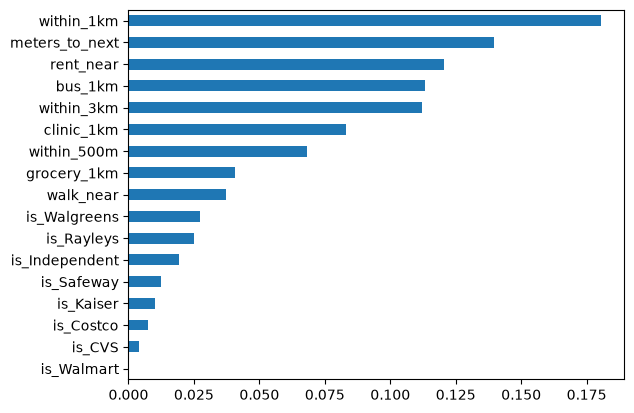

In [40]:
print(ev[ev.y == 0].nlargest(3, 'risk')[['name', 'lat', 'lon', 'risk']]) #rated risky, still open
print(ev[ev.y == 1].nsmallest(2, 'risk')[['name', 'lat', 'lon', 'risk']]) #rated safe, but closed

pd.Series(model.feature_importances_, index=features).sort_values().plot.barh() #which features mattered most

## Step 9. Map and charts
Owner: ___  
Save charts to `FIG_DIR` and the folium map to `MAP_DIR`. Two-sided bars, 800 m before/after, model vs baseline, "last pharmacy standing" list.

In [ ]:
# Step 9.0: load the saved Step 5 outputs and print the ledger. Reads files only, no variables from earlier steps.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import folium
from folium.plugins import GroupedLayerControl
from sklearn.neighbors import BallTree
from sklearn.cluster import DBSCAN

EARTH_M = 6371 * 1000
TIERS = ["low", "middle", "high"]
TIER_NAME = {"low": "Cheapest third", "middle": "Middle third", "high": "Priciest third"}

homes = pd.read_csv(OUT_DIR / "home_access.csv")
ph = pd.read_csv(OUT_DIR / "pharmacies_clean.csv",
                 usecols=["place_id", "lat", "lon", "permanently_closed", "chain_shutdown", "real_closure", "m_to_open"])
two_excl = pd.read_csv(OUT_DIR / "two_sided_excl.csv", index_col=0)
two_incl = pd.read_csv(OUT_DIR / "two_sided_incl.csv", index_col=0)
county = pd.read_csv(OUT_DIR / "county_breakdown.csv")
county_ph = pd.read_csv(OUT_DIR / "pharmacy_closures_by_county.csv")
tiers_ph = pd.read_csv(OUT_DIR / "pharmacy_rent_tiers.csv")
handcheck = pd.read_csv(OUT_DIR / "handcheck_done.csv")

ledger = {
    "homes (134,835)": len(homes),
    "pharmacy listings (1,692)": len(ph),
    "open listings (1,168)": int((~ph["permanently_closed"]).sum()),
    "real closures (358)": int(ph["real_closure"].sum()),
    "model pharmacies with rent tier (1,523)": len(tiers_ph),
    "counties (9)": len(county),
    "hand-checked (40)": len(handcheck),
}
for k, v in ledger.items():
    print(f"{k:42s} {v:,}")
assert list(ledger.values()) == [134835, 1692, 1168, 358, 1523, 9, 40], "a saved file changed since Step 5: stop and find out why"
assert homes["zpid"].is_unique and homes[["latitude", "longitude", "m_after", "rent_tier"]].notna().all().all()
assert two_excl.shape == (7, 4) and two_incl.shape == (7, 4)

In [ ]:
# Step 9.1: one style for every figure, plus a helper that saves to FIG_DIR.
plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "axes.spines.top": False, "axes.spines.right": False})
TIER_COLOR = {"low": "#9ecae1", "middle": "#4292c6", "high": "#084594"}

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    print("saved", FIG_DIR / name)

In [ ]:
# Step 9.2: for every home, distance to its nearest open pharmacy SITE and to the second-nearest site.
# A site = open listings within 50 m of each other (same rule as Step 7.2), so a store listed twice is not its own backup.
open_ph = ph.loc[~ph["permanently_closed"]].reset_index(drop=True)
open_rad = np.radians(open_ph[["lat", "lon"]].to_numpy())          # [lat, lon], radians
open_ph["site"] = DBSCAN(eps=50 / EARTH_M, min_samples=1, metric="haversine",
                         algorithm="ball_tree").fit(open_rad).labels_
site_sizes = open_ph["site"].value_counts()
print("open listings:", len(open_ph), "| open sites:", open_ph["site"].nunique(), "(expected 953) | largest site:", site_sizes.max())
assert open_ph["site"].nunique() == 953

K = 25   # nearest listings to look through; must be larger than the biggest site so a second site is always found
assert site_sizes.max() < K
tree = BallTree(open_rad, metric="haversine")
homes_rad = np.radians(homes[["latitude", "longitude"]].to_numpy())
dist_rad, idx = tree.query(homes_rad, k=K)                          # sorted nearest first
dist_m = dist_rad * EARTH_M
site_of = open_ph["site"].to_numpy()[idx]                           # site number of each of the K neighbours

other_site = site_of != site_of[:, [0]]                             # True where the neighbour is a different site
assert other_site.any(axis=1).all(), "some home has no second site in its K nearest listings: raise K"
first_other = other_site.argmax(axis=1)                             # position of the first listing at another site
rows = np.arange(len(homes))
homes["m_site1"] = dist_m[:, 0]
homes["m_site2"] = dist_m[rows, first_other]

# Checks: units and agreement with Step 5
print(homes[["m_after", "m_site1", "m_site2"]].describe().round(0).T[["min", "50%", "max"]])
assert np.allclose(homes["m_site1"], homes["m_after"], atol=1), "nearest site differs from Step 5's m_after: units or set mix-up"
assert (homes["m_site2"] >= homes["m_site1"] - 1e-6).all(), "second-nearest is closer than nearest: columns swapped"

## Step 10. Package
Owner: ___  
Restart and run all from the raw files. Update the README.

In [ ]:
# TODO